<a href="https://colab.research.google.com/github/aashish7542/ai-learning/blob/main/Monte_Carlo_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Let's do some random coding first.

In [ ]:
import numpy as np

prices = np.array([100, 105, 102, 108, 104], dtype=float)
returns = prices[1:] / prices[:-1] - 1
print(returns)



[ 0.05       -0.02857143  0.05882353 -0.03703704]


This is called vectorization: expressing the calculation as array operations instead of writing a Python loop.

In [ ]:
growth_factor = 1 + returns
capital = 1000
values = capital * np.cumprod(growth_factor)
print(values)

[1050. 1020. 1080. 1040.]


We stored our commulative gains/loss in print, showing the overall growth of our capital. Now we will do the same thing over a randomly generated distribution.

Final value: $939.39


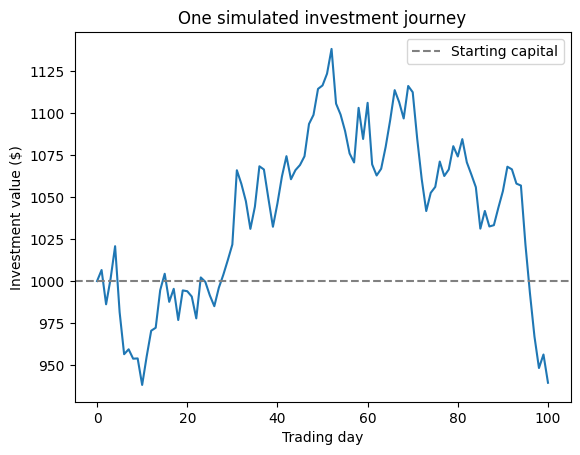

In [ ]:
rng = np.random.default_rng(42)

sim_returns = rng.normal(
    loc=0.0005,  # mean daily return: 0.05%
    scale=0.02,  # daily standard deviation: 2%
    size=100    # 100 trading days
)

capital = 1000
sim_values = capital*(np.cumprod(sim_returns + 1))
print(f"Final value: ${sim_values[-1]:.2f}")

import matplotlib.pyplot as plt

# Include the starting capital at day 0
values_with_start = np.insert(sim_values, 0, capital)

plt.plot(values_with_start)
plt.axhline(capital, color="gray", linestyle="--", label="Starting capital")
plt.xlabel("Trading day")
plt.ylabel("Investment value ($)")
plt.title("One simulated investment journey")
plt.legend()
plt.show()

Now we generate a data for multiple days. Previously, it was for only one day, so 1D array, now its 2D array.

In [ ]:
rng = np.random.default_rng(42)

sim_returns = rng.normal(
    loc=0.0005,
    scale=0.02,
    size=(1000, 100)
)

sim_values = capital*(np.cumprod(sim_returns + 1, axis=1))

Now, we have a record of our capital returned over 100 days. We will record the final position of our capital for each days, and calculate the fraction of simulations that lost money

In [ ]:
final_values = sim_values[:,-1]

losses = final_values < capital
n_loss = losses.sum()
loss_probability = n_loss / len(final_values)
print(losses.mean())

print(f"Fraction of simulations that lost money: {loss_probability:.2%}")


0.464
Fraction of simulations that lost money: 46.40%


We will investigate more into the loss.

In [ ]:
p5, median, p95 = np.percentile(final_values, [5, 50, 95])

print(f"5th percentile:  ${p5:.2f}")
print(f"Median:          ${median:.2f}")
print(f"95th percentile: ${p95:.2f}")

5th percentile:  $730.69
Median:          $1019.72
95th percentile: $1432.92


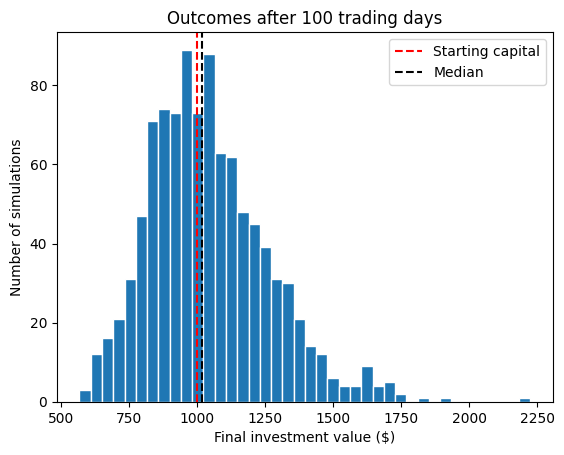

In [ ]:
plt.hist(final_values, bins=40, edgecolor="white")
plt.axvline(capital, color="red", linestyle="--", label="Starting capital")
plt.axvline(median, color="black", linestyle="--", label="Median")
plt.xlabel("Final investment value ($)")
plt.ylabel("Number of simulations")
plt.title("Outcomes after 100 trading days")
plt.legend()
plt.show()

Now we will increase the volatility and see how it impacts our result.

In [ ]:
rng = np.random.default_rng(42)

high_vol_returns = rng.normal(
    loc=0.0005,
    scale=0.04,
    size=(1000, 100)
)

high_vol_values = capital * np.cumprod(1 + high_vol_returns, axis=1)
high_vol_final = high_vol_values[:, -1]

for label, outcomes in [("2% volatility", final_values),
                        ("4% volatility", high_vol_final)]:
    p5, median, p95 = np.percentile(outcomes, [5, 50, 95])
    print(f"{label}: loss probability = {(outcomes < capital).mean():.1%}, "
          f"median = ${median:.2f}, "
          f"middle 90% = ${p5:.2f}–${p95:.2f}")

2% volatility: loss probability = 46.4%, median = $1019.72, middle 90% = $730.69–$1432.92
4% volatility: loss probability = 55.6%, median = $950.18, middle 90% = $487.48–$1865.80


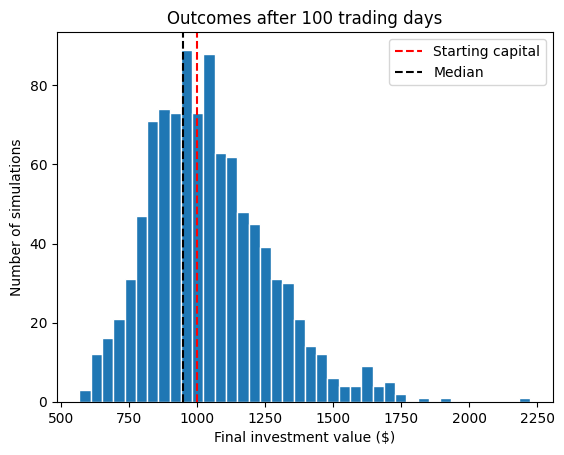

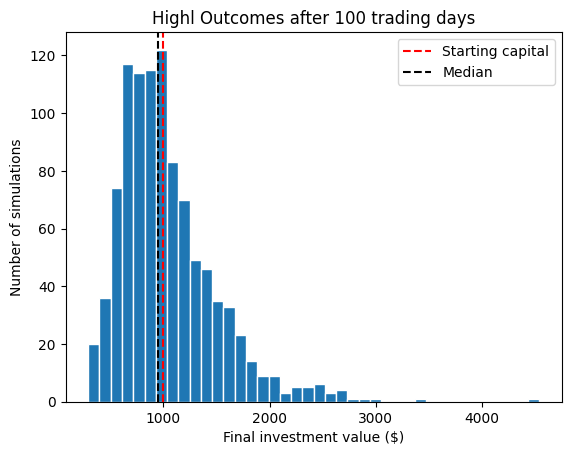

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(final_values, bins=40, edgecolor="white")
plt.axvline(capital, color="red", linestyle="--", label="Starting capital")
plt.axvline(median, color="black", linestyle="--", label="Median")
plt.xlabel("Final investment value ($)")
plt.ylabel("Number of simulations")
plt.title("Outcomes after 100 trading days")
plt.legend()
plt.show()

plt.figure()
plt.hist(high_vol_final, bins=40, edgecolor="white")
plt.axvline(capital, color="red", linestyle="--", label="Starting capital")
plt.axvline(median, color="black", linestyle="--", label="Median")
plt.xlabel("Final investment value ($)")
plt.ylabel("Number of simulations")
plt.title("Highl Outcomes after 100 trading days")
plt.legend()
plt.show()